In [2]:
import pandas as pd
pd.set_option('display.max_columns', None)


In [3]:

df = pd.read_csv("/home/n/Documents/inbound_lead_analysis/leads_cleaned.csv")

df.loc[df['Email_replied'] == False, 'Reply_date'] = None

In [4]:
df['Reply_date'] = pd.to_datetime(df['Reply_date'])
df['Form_submission_date'] = pd.to_datetime(df['Form_submission_date'])
df['First_email_sent_date'] = pd.to_datetime(df['First_email_sent_date'])
column_to_move = df.pop('Reply_date')
df.insert(8, 'Reply_date', column_to_move)


In [5]:
df["days_to_first_email"] = df["First_email_sent_date"] - df['Form_submission_date']
df["days_to_reply"] = df["Reply_date"] - df["First_email_sent_date"]
for col in ( 'days_to_first_email','days_to_reply'):
   df[col] = df[col].astype(str).str.replace('[^0-9]', '', regex=True)
   df[col] = pd.to_numeric(df[col]).astype('Int64')


In [6]:
mask = df['Company_size'].str.contains('-', regex=False)
df['min_size'] = df['Company_size'].str.replace('+','', regex=False).str.split('-').str[0].astype(int)
df['max_size'] = pd.NA
df.loc[mask, 'max_size'] = (
    df.loc[mask,'Company_size'].str.split('-').str[1].astype(int)
)    
df['ICP_match'] = (
    (df['min_size'] <= 500) &
    ((df['max_size'] >= 50) | (df['max_size'].isna())) &
    (df['Funding_status'].isin(['Series A','Series B','Series C']))
)


In [7]:
cols = ['Sales_team_size', 'Growth_team_size', 'days_to_first_email', 'days_to_reply']

mid = (df['min_size'] + df['max_size']) / 2


summary_df = df[cols].describe()

summary_df['Company_size'] = [
    float(mid.sum()),
    float(mid.mean()),
    
    float(mid.std()),
   
    float(df['min_size'].min()),

    float(mid.quantile(0.25)), 
     float(mid.median()),
    float(mid.quantile(0.75)),
        float(df['max_size'].max())
]
summary_df

,Sales_team_size,Growth_team_size,days_to_first_email,days_to_reply,Company_size
count,100.000000,100.000000,100.0,54.0,22364.000000
mean,59.880000,25.710000,3.19,5.203704,254.136364
std,51.153419,23.416861,2.368544,3.024302,245.310883
min,4.000000,1.000000,0.0,1.0,1.000000
25%,20.000000,9.000000,1.0,2.25,30.500000
50%,69.000000,20.000000,3.0,4.5,125.500000
75%,90.500000,46.250000,5.0,7.75,350.500000
max,145.000000,63.000000,7.0,10.0,1000.000000


In [7]:
#binary funnel metrics
leads= 100

replyrate = float(df['Email_replied'].sum()/leads*100)
qualrate = float(df['Qualified_lead'].sum() / float(df['Email_replied'].sum())*100)
meetingrate = float(df['Meeting_booked'].sum() / float(df['Qualified_lead'].sum())*100)

cols = [replyrate,qualrate,meetingrate]
b = pd.DataFrame([cols],columns=['reply_rate','qualify_rate','conversion_rate'])

In [8]:
#job level analysis
j = pd.DataFrame()

j = (
    df.groupby('Job_level')
    .agg(
        Leads=('Job_level','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

j['conversion_rate'] = j['conversion_rate']* 100
j['qualify_rate']= j['qualify_rate']* 100
j['reply_rate']= j['reply_rate']*100
j['%_leads'] = j['Leads'] / len(df) * 100

column_to_move = j.pop('%_leads')
j.insert(1, '%_leads', column_to_move)

j

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate
Job_level,,,,,
Director,10,10.0,60.000000,30.000000,10.000000
Founder,12,12.0,58.333333,16.666667,16.666667
IC,36,36.0,58.333333,22.222222,5.555556
Manager,34,34.0,41.176471,17.647059,11.764706
VP,8,8.0,75.000000,25.000000,12.500000


In [9]:
#job title analysis
t = pd.DataFrame()

t = (
    df.groupby('Job_title')
    .agg(
        Leads=('Job_title','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

t['conversion_rate'] = t['conversion_rate']* 100
t['qualify_rate']= t['qualify_rate']* 100
t['reply_rate']= t['reply_rate']*100
t['%_leads'] = t['Leads'] / len(df) * 100

column_to_move = t.pop('%_leads')
t.insert(1, '%_leads', column_to_move)

t

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate
Job_title,,,,,
Account Executive,28,28.0,67.857143,25.000000,7.142857
CEO,6,6.0,66.666667,33.333333,33.333333
Director of Sales,10,10.0,60.000000,30.000000,10.000000
Founder,6,6.0,50.000000,0.000000,0.000000
Growth Manager,4,4.0,75.000000,0.000000,0.000000
Head of Growth,6,6.0,16.666667,16.666667,0.000000
Marketing Manager,13,13.0,46.153846,30.769231,23.076923
Revenue Operations Manager,11,11.0,36.363636,9.090909,9.090909
Sales Development Representative,8,8.0,25.000000,12.500000,0.000000


In [10]:
#company size analysis
c = pd.DataFrame()

c = (
    df.groupby('Company_size')
    .agg(
        Leads=('Company_size','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

c['conversion_rate'] = c['conversion_rate']* 100
c['qualify_rate']=c['qualify_rate']* 100
c['reply_rate']= c['reply_rate']*100
c['%_leads'] = c['Leads'] / len(df) * 100

column_to_move = c.pop('%_leads')
c.insert(1, '%_leads', column_to_move)

c

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate
Company_size,,,,,
1-10,15,15.0,46.666667,13.333333,6.666667
1000+,12,12.0,58.333333,41.666667,0.000000
11-50,9,9.0,22.222222,0.000000,0.000000
201-500,26,26.0,50.000000,19.230769,11.538462
501-1000,13,13.0,92.307692,15.384615,7.692308
51-200,25,25.0,52.000000,28.000000,20.000000


In [11]:
#company size analysis
f = pd.DataFrame()

f = (
    df.groupby('Funding_status')
    .agg(
        Leads=('Funding_status','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

f['conversion_rate'] = f['conversion_rate']* 100
f['qualify_rate']=f['qualify_rate']* 100
f['reply_rate']= f['reply_rate']*100
f['%_leads'] = f['Leads'] / len(df) * 100

column_to_move = f.pop('%_leads')
f.insert(1, '%_leads', column_to_move)

f

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate
Funding_status,,,,,
Bootstrapped,13,13.0,53.846154,23.076923,23.076923
Public,25,25.0,76.000000,28.000000,4.000000
Seed,15,15.0,46.666667,13.333333,6.666667
Series A,9,9.0,22.222222,0.000000,0.000000
Series B,31,31.0,48.387097,22.580645,16.129032
Series C,7,7.0,57.142857,28.571429,0.000000


In [15]:
#rep analysis
s = pd.DataFrame()

s = (
    df.groupby('Sales_owner')
    .agg(
        Leads=('Sales_owner','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean'),
        days_to_first_email= ('days_to_first_email','mean')
    )
)

s['conversion_rate'] = s['conversion_rate']* 100
s['qualify_rate']=s['qualify_rate']* 100
s['reply_rate']= s['reply_rate']*100
s['%_leads'] = s['Leads'] / len(df) * 100

column_to_move = s.pop('%_leads')
s.insert(1, '%_leads', column_to_move)

s

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate,days_to_first_email
Sales_owner,,,,,,
Inbound_Team,19,19.0,42.105263,10.526316,5.263158,2.684211
Rep_A,21,21.0,61.904762,33.333333,14.285714,4.190476
Rep_B,15,15.0,60.000000,13.333333,6.666667,2.266667
Rep_C,24,24.0,58.333333,29.166667,16.666667,2.916667
Rep_D,21,21.0,47.619048,14.285714,4.761905,3.619048


In [15]:
#icp analysis
i = pd.DataFrame()

i = (
    df.groupby('ICP_match')
    .agg(
        Leads=('ICP_match','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

i['conversion_rate'] = i['conversion_rate']* 100
i['qualify_rate']=i['qualify_rate']* 100
i['reply_rate']= i['reply_rate']*100
i['%_leads'] = i['Leads'] / len(df) * 100

column_to_move = i.pop('%_leads')
i.insert(1, '%_leads', column_to_move)

i

,Leads,%_leads,reply_rate,qualify_rate,conversion_rate
ICP_match,,,,,
False,53,53.0,62.264151,22.641509,9.433962
True,47,47.0,44.680851,19.148936,10.638298


In [14]:
df.to_csv('clean_data.csv')
summary_df.to_csv('summary.csv')
j.to_csv('job_level.csv')
t.to_csv('job_title.csv')
c.to_csv('company_size.csv')
s.to_csv('sales_owner.csv') 
f.to_csv('funding_status.csv') 
i.to_csv('ICP_Match.csv') 
b.to_csv('Funnel_performance.csv')

In [23]:
#plotting graphs
import matplotlib.pyplot as plt
import numpy as np
df['Email_replied'] = df['Email_replied'].astype(int)

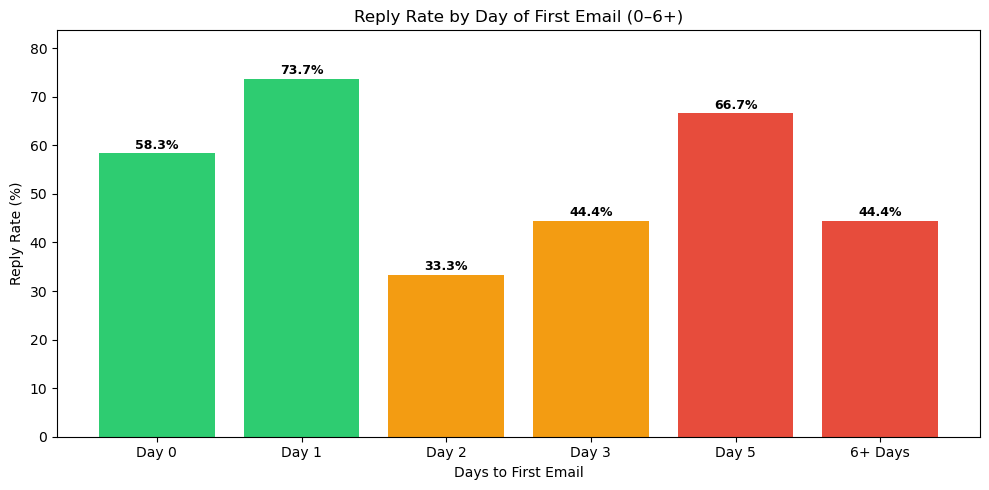

             Reply Rate (%)  Sample Size
email_speed                             
Day 0                  58.3           12
Day 1                  73.7           19
Day 2                  33.3           15
Day 3                  44.4           18
Day 5                  66.7           18
6+ Days                44.4           18


In [63]:
import pandas as pd
import matplotlib.pyplot as plt

# Cap at 7 days, group 7+ together
df['email_speed'] = df['days_to_first_email'].apply(
    lambda x: '6+ Days' if x >= 6 else f'Day {int(x)}'
)

# Define order
order = [f'Day {i}' for i in range(8)] + ['6+ Days']
order = [o for o in order if o in df['email_speed'].unique()]

# Calculate reply rate
reply_rate = df.groupby('email_speed', observed=True)['Email_replied'].mean() * 100
reply_rate = reply_rate.reindex(order)

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if i < 2 else '#f39c12' if i < 4 else '#e74c3c' 
          for i in range(len(reply_rate))]
bars = ax.bar(reply_rate.index, reply_rate.values, color=colors)

# Add percentage labels on top of bars
for bar, val in zip(bars, reply_rate.values):
    if not pd.isna(val):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=9)

ax.set_xlabel('Days to First Email')
ax.set_ylabel('Reply Rate (%)')
ax.set_title('Reply Rate by Day of First Email (0–6+)')
ax.set_ylim(0, reply_rate.max() + 10)
plt.tight_layout()
plt.savefig('reply_rate_by_email.png', dpi=300, bbox_inches='tight')
plt.show()

# Print raw numbers + sample sizes
summary = pd.DataFrame({
    'Reply Rate (%)': reply_rate.round(1),
    'Sample Size': df.groupby('email_speed', observed=True)['Email_replied'].count()
}).reindex(order)
print(summary.to_string())

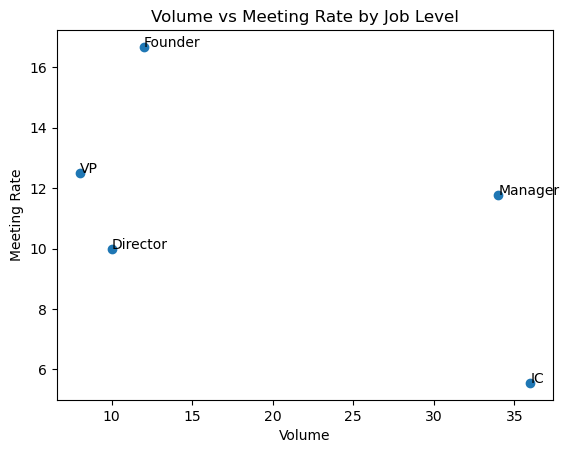

In [62]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.scatter(j['Leads'], j['conversion_rate'])

for idx, row in j.iterrows():
    ax.annotate(idx, (row['Leads'], row['conversion_rate']))

ax.set_xlabel('Volume')
ax.set_ylabel('Meeting Rate')
ax.set_title('Volume vs Meeting Rate by Job Level')
plt.savefig('volume_vs_meeting_rate_by_level.png', dpi=300, bbox_inches='tight')
plt.show()

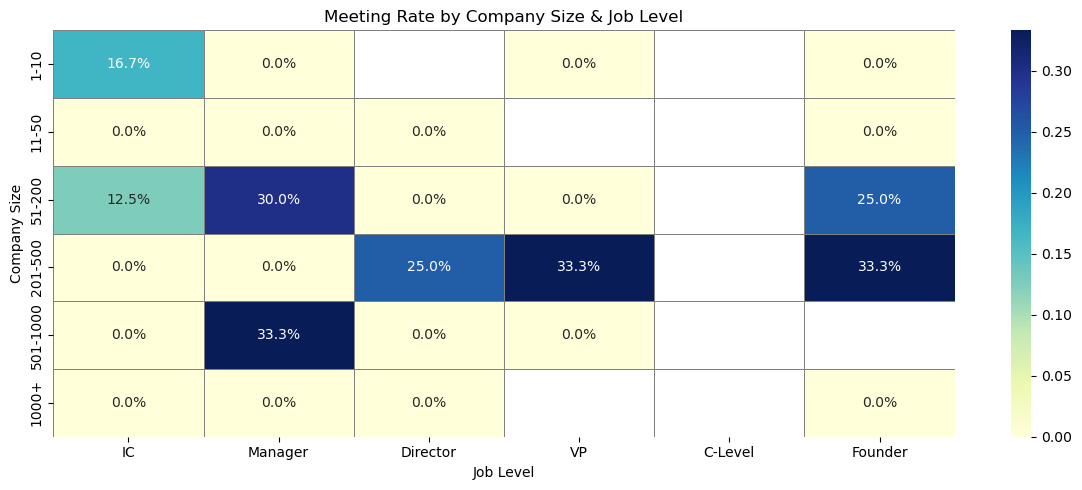

In [69]:
import seaborn as sns

level_order = ['IC', 'Manager', 'Director', 'VP', 'C-Level', 'Founder']
size_order = ['1-10', '11-50', '51-200', '201-500', '501-1000', '1000+']

pivot = df.groupby(['Company_size', 'Job_level'], observed=True)['Meeting_booked'] \
          .mean().unstack('Job_level')

# Reorder both axes
pivot = pivot.reindex(index=size_order, columns=level_order)

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='YlGnBu',
            linewidths=0.5, linecolor='grey')
plt.title('Meeting Rate by Company Size & Job Level')
plt.xlabel('Job Level')
plt.ylabel('Company Size')
plt.tight_layout()
plt.savefig('Meeting_rate_by_size_and_job.png', dpi=300, bbox_inches='tight')
plt.show()

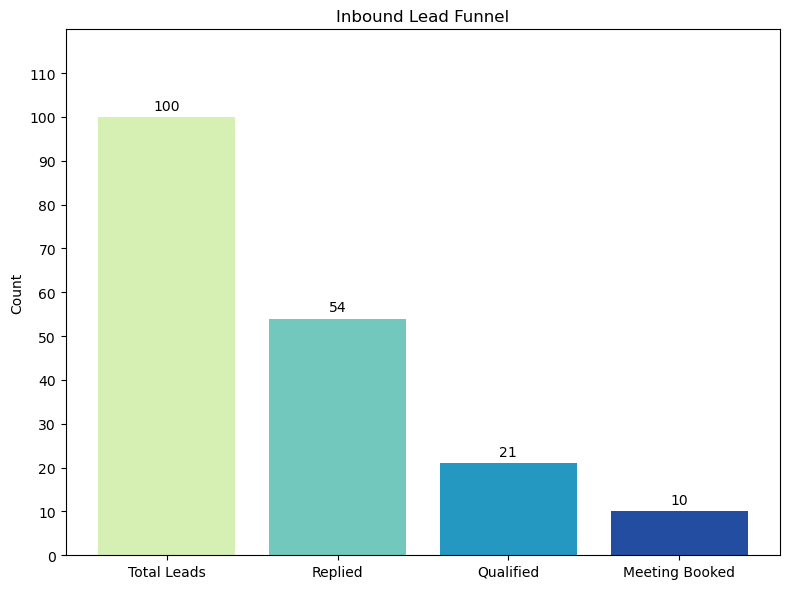

In [66]:
stages = ['Total Leads', 'Replied', 'Qualified', 'Meeting Booked']
values = [
    len(df),
    df['Email_replied'].sum(),
    df['Qualified_lead'].sum(),
    df['Meeting_booked'].sum()
]

plt.figure(figsize=(8, 6))
bars = plt.bar(stages, values, color=sns.color_palette('YlGnBu', 4))

for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,  # +1 instead of +100
             f'{val:,}', ha='center', va='bottom')

plt.title('Inbound Lead Funnel')
plt.ylabel('Count')
plt.ylim(0, 120)  # just above 100

import numpy as np
plt.yticks(np.arange(0, 120, 10))  # tick every 10

plt.tight_layout()
plt.savefig('funnel_chart.png', dpi=300, bbox_inches='tight')
plt.show()

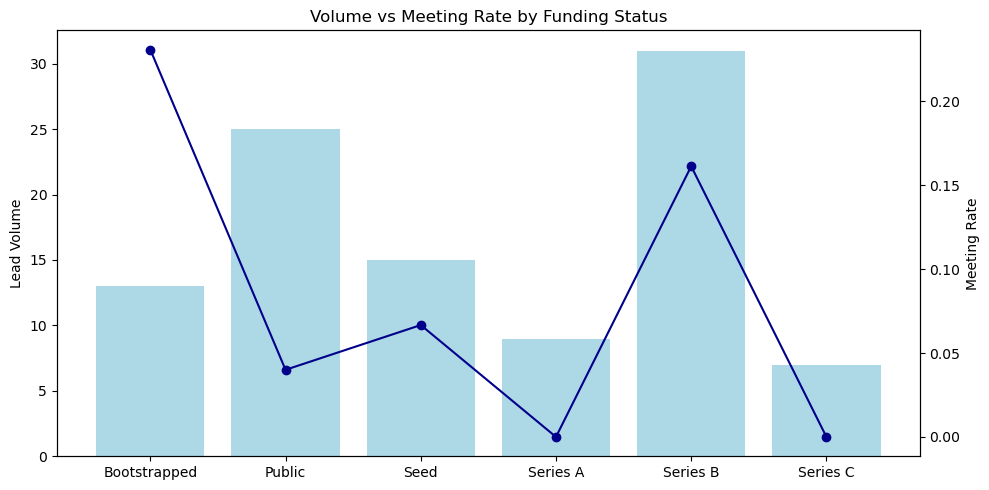

In [67]:
funding_stats = df.groupby('Funding_status').agg(
    Leads=('Lead_id', 'count'),
    meeting_rate=('Meeting_booked', 'mean')
)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.bar(funding_stats.index, funding_stats['Leads'], color='lightblue', label='Volume')
ax2.plot(funding_stats.index, funding_stats['meeting_rate'], 'o-', color='darkblue', label='Meeting Rate')

ax1.set_ylabel('Lead Volume')
ax2.set_ylabel('Meeting Rate')
plt.title('Volume vs Meeting Rate by Funding Status')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('volume_vs_meeting_rate_by_funding.png', dpi=300, bbox_inches='tight')
plt.show()

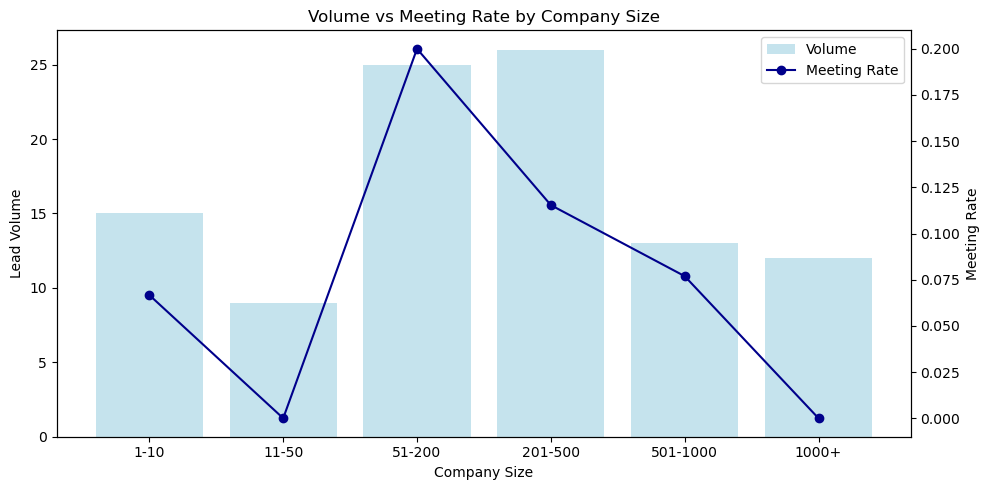

In [68]:
company_stats = df.groupby('Company_size', observed=True).agg(
    Leads=('Lead_id', 'count'),
    meeting_rate=('Meeting_booked', 'mean')
).reindex(size_order)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.bar(company_stats.index, company_stats['Leads'], color='lightblue', label='Volume', alpha=0.7)
ax2.plot(company_stats.index, company_stats['meeting_rate'], 'o-', color='darkblue', label='Meeting Rate')

ax1.set_ylabel('Lead Volume')
ax2.set_ylabel('Meeting Rate')
ax1.set_xlabel('Company Size')
plt.title('Volume vs Meeting Rate by Company Size')
plt.xticks(rotation=45)

# Combined legend for both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.savefig('volume_vs_meeting_rate_by_size.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
df

,Lead_id,Contact_id,Lead_name,Company_domain,Job_title,Job_level,Form_submission_date,First_email_sent_date,Reply_date,Email_replied,Qualified_lead,Meeting_booked,Sales_owner,Company_size,Funding_status,Sales_team_size,Growth_team_size,days_to_first_email,days_to_reply,min_size,max_size,ICP_match
0,L0001,C0001,Emerson Martin,agencyhub.co,Account Executive,IC,2026-01-15,2026-01-22,NaT,False,False,False,Inbound_Team,1-10,Seed,6,1,7,<NA>,1,10,False
1,L0002,C0002,Casey Johnson,revopscloud.com,Marketing Manager,Manager,2026-01-09,2026-01-14,2026-01-23,True,False,False,Rep_A,201-500,Series B,69,20,5,9,201,500,True
2,L0003,C0003,Jordan Wilson,revopscloud.com,Director of Sales,Director,2026-02-08,2026-02-11,NaT,False,False,False,Rep_D,201-500,Series B,69,20,3,<NA>,201,500,True
3,L0004,C0004,Emerson Martin,saasworks.ai,Director of Sales,Director,2026-02-27,2026-03-02,2026-03-04,True,False,False,Inbound_Team,51-200,Bootstrapped,20,9,3,2,51,200,False
4,L0005,C0005,Alex Martin,saasworks.ai,Marketing Manager,Manager,2026-01-19,2026-01-20,NaT,False,False,False,Inbound_Team,51-200,Bootstrapped,20,9,1,<NA>,51,200,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,L0096,C0096,Skyler White,fintechflow.com,Founder,Founder,2026-01-31,2026-02-01,NaT,False,False,False,Rep_C,11-50,Series A,4,6,1,<NA>,11,50,True
96,L0097,C0097,Avery Harris,enterprisetech.com,Account Executive,IC,2026-01-08,2026-01-08,NaT,False,False,False,Rep_D,1000+,Public,128,63,0,<NA>,1000,<NA>,False
97,L0098,C0098,Riley Jackson,startupco.com,Sales Development Representative,IC,2026-03-01,2026-03-08,NaT,False,False,False,Rep_D,501-1000,Public,145,62,7,<NA>,501,1000,False
98,L0099,C0099,Quinn Anderson,agencyhub.co,Account Executive,IC,2026-01-08,2026-01-11,2026-01-21,True,True,False,Inbound_Team,1-10,Seed,6,1,3,10,1,10,False


In [18]:
#icp analysis

df['newICP'] = (
    (df['min_size'] <= 200) &
    ((df['max_size'] >= 51) | (df['max_size'].isna())) &
    (df['Funding_status'].isin(['Bootstrapped'])) &
    (df['Job_title'].isin(['CEO','Marketing Manager']))
)

icp = pd.DataFrame()

icp = (
    df.groupby('newICP')
    .agg(
        Leads=('newICP','size'),
        reply_rate=('Email_replied', 'mean'),
        qualify_rate=('Qualified_lead', 'mean') ,
        conversion_rate= ('Meeting_booked', 'mean')
    )
)

icp['conversion_rate'] = icp['conversion_rate']* 100
icp['qualify_rate']=icp['qualify_rate']* 100
icp['reply_rate']= icp['reply_rate']*100
icp['%_leads'] = icp['Leads'] / len(df) * 100

column_to_move = icp.pop('%_leads')
icp.insert(1, '%_leads', column_to_move)

icp
icp.to_csv('New_ICP.csv')